In [1]:
from langgraph.graph import StateGraph,START,MessagesState
from langchain_groq import ChatGroq
from dotenv import load_dotenv
from langgraph.checkpoint.memory import InMemorySaver
from langchain.messages import RemoveMessage

In [2]:
load_dotenv()

True

In [3]:
model=ChatGroq(model="openai/gpt-oss-20b",temperature=0)

In [5]:
def chat(state:MessagesState):
    response=model.invoke(state["messages"])
    return {"messages":[response]}

def delete_old_messages(state:MessagesState):
    msgs=state["messages"]
    if len(msgs)>10:
        to_remove=msgs[:6]
        return {"messages":[RemoveMessage(id=m.id) for m in to_remove]}
    return {}

In [6]:
builder=StateGraph(MessagesState)
builder.add_node("chat",chat)
builder.add_node("cleanup",delete_old_messages)
builder.add_edge(START,"chat")
builder.add_edge("chat","cleanup")
builder.add_edge("cleanup","__end__")

In [7]:
checkpointer=InMemorySaver()
graph=builder.compile(checkpointer=checkpointer)

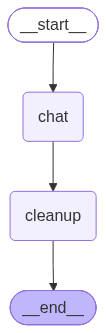

In [8]:
graph

In [9]:
config= {"configurable": {"thread_id":"t1"}}

In [10]:
graph.invoke({"messages":[{"role":"user","content":"hii! my name is nitish"}]},config)
graph.invoke({"messages":[{"role":"user","content":"tell me about langgraph"}]},config)
graph.invoke({"messages":[{"role":"user","content":"now explain checkpointer"}]},config)
graph.invoke({"messages":[{"role":"user","content":"what is langchain"}]},config)
graph.invoke({"messages":[{"role":"user","content":"what is quantum mechanics"}]},config)
graph.invoke({"messages":[{"role":"user","content":"what is genai"}]},config)
graph.invoke({"messages":[{"role":"user","content":"what is my name"}]},config)

{'messages': [HumanMessage(content='what is langchain', additional_kwargs={}, response_metadata={}, id='b85a414d-a468-4428-8517-6f1337095c14'),
  AIMessage(content='## LangChain – The “Framework for LLM‑Powered Applications”\n\n> **TL;DR**  \n> LangChain is a Python library that lets you build *complex* applications around large language models (LLMs) by wiring together **prompts, memory, tools, and external services** in a modular, testable way.  \n> Think of it as a “low‑code” platform for turning an LLM into a *full‑stack* app: chatbots, data‑analysis assistants, code generators, and more.\n\n---\n\n### 1. Why LangChain?\n\n| Pain Point | Traditional Solution | LangChain Advantage |\n|------------|----------------------|---------------------|\n| **Prompt engineering** | Manually craft prompts, copy‑paste, hard‑to‑maintain | Reusable `PromptTemplate` objects, automatic token counting, chainable prompts |\n| **Stateful conversations** | Store context in a DB or pass a growing prompt |

In [11]:
snap=graph.get_state(config)
print("stored messages after cleanup",len(snap.values["messages"]))

stored messages after cleanup 8
